# 04. Synthetic Multi-Level Baselines

## Objective

This notebook establishes initial machine learning baselines for the multi-level
financial scam analysis framework.

Unlike the previous notebook, which focused on binary scam-versus-legitimate
classification, this experiment investigates three additional prediction tasks
using the corrected synthetic financial scam dataset:

1. Scam subtype classification (13 classes).
2. Fraudulent intent classification (5 classes).
3. Social-engineering tactic recognition (9-label multi-label classification).

## Experimental approach

- Dataset: `synthetic_financial_scams_v3_corrected_processed.csv`
- Training split: 80%
- Validation split: 10%
- Test split: 10%
- Random seed: 42
- Initial representation: Word-level TF-IDF.
- Initial models: Classical machine learning baselines.
- Evaluation: Task-appropriate classification metrics.

The training split will be used for model fitting, while the validation split
will support model comparison and selection. The test split will remain
untouched until final evaluation.

## Important limitations

The dataset is synthetic, and its labels are generated rather than independently
annotated by human experts. Therefore, results from this notebook measure
performance on the constructed synthetic dataset and must not be interpreted
as evidence of real-world generalization.

The three prediction tasks will initially be evaluated independently. Their
results will provide a foundation for subsequent multi-task modeling and
explainability experiments.

In [1]:
import ast
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "synthetic_financial_scams_v3_corrected_processed.csv"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: d:\Programs and Codes\financial-scam-analysis
Dataset path: d:\Programs and Codes\financial-scam-analysis\data\processed\synthetic_financial_scams_v3_corrected_processed.csv
Dataset exists: True


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(df.head(5))

Dataset loaded successfully.
Shape: 7,800 rows × 36 columns


,record_id,original_text,normalized_text,label,channel,original_channel,is_email_gateway,has_gateway_headers,source,source_url,...,char_count_normalized,word_count_normalized,placeholder_count_original,placeholder_count_normalized,scenario_family,generation_template_id,generation_scenario,risk_or_safety_note,language,communication_type
0,SYN3C-00001,Action Required: We detected an unauthorized s...,Action Required: We detected an unauthorized s...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,320,44,0,1,new_device_browser_login,ACC_NEW_DE_01,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
1,SYN3C-00002,Action Required: A new device located in Dalla...,Action Required: A new device located in Dalla...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,359,54,0,1,new_device_browser_login,ACC_NEW_DE_02,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
2,SYN3C-00003,Security Alert: We detected an unauthorized si...,Security Alert: We detected an unauthorized si...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,296,45,0,1,new_device_browser_login,ACC_NEW_DE_03,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
3,SYN3C-00004,Subject: Official Notice Regarding Reference #...,Subject: Official Notice Regarding Reference #...,1,email,email,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,402,52,0,3,new_device_browser_login,ACC_NEW_DE_04,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
4,SYN3C-00005,Action Required: A new device located in Seatt...,Action Required: A new device located in Seatt...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,409,61,0,1,new_device_browser_login,ACC_NEW_DE_05,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam


In [3]:
# Inspect the complete schema

schema = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique(dropna=True).values
})

display(schema)

,column,dtype,non_null,missing,unique_values
0,record_id,str,7800,0,7800
1,original_text,str,7800,0,7653
2,normalized_text,str,7800,0,7400
3,label,int64,7800,0,1
4,channel,str,7800,0,4
5,original_channel,str,7800,0,4
6,is_email_gateway,bool,7800,0,1
7,has_gateway_headers,bool,7800,0,1
8,source,str,7800,0,1
9,source_url,str,7800,0,1


In [4]:
# Inspect target labels

target_columns = [
    "scam_subtype",
    "fraudulent_intent",
    "social_engineering_tactics"
]

for column in target_columns:
    print(f"\n{'=' * 65}")
    print(f"{column}")
    print(f"Unique values: {df[column].nunique()}")

    if column != "social_engineering_tactics":
        display(
            df[column]
            .value_counts()
            .rename_axis("class")
            .reset_index(name="count")
        )
    else:
        print("\nSample serialized values:")
        for value in df[column].drop_duplicates().head(10):
            print(repr(value))


scam_subtype
Unique values: 13


,class,count
0,account_verification,600
1,card_transaction_alert,600
2,refund_chargeback,600
3,invoice_payment_request,600
4,loan_offer,600
5,investment_crypto,600
6,prize_reward,600
7,tax_payment,600
8,job_task_commission,600
9,romance_financial_manipulation,600



fraudulent_intent
Unique values: 5


,class,count
0,induce_payment_or_transfer,3664
1,obtain_personal_or_financial_information,1801
2,obtain_credentials_or_codes,1141
3,gain_account_or_device_access,597
4,induce_fraudulent_investment,597



social_engineering_tactics
Unique values: 213

Sample serialized values:
'["secrecy"]'
'["authority_impersonation", "secrecy"]'
'["authority_impersonation"]'
'["false_legitimacy"]'
'["urgency", "fear_or_threat"]'
'["secrecy", "authority_impersonation"]'
'["authority_impersonation", "urgency", "secrecy"]'
'["fear_or_threat"]'
'["secrecy", "urgency"]'
'[]'


In [5]:
# Validate and inspect tactic labels

tactic_lists = df["social_engineering_tactics"].apply(json.loads)

all_tactics = sorted({
    tactic
    for tactics in tactic_lists
    for tactic in tactics
})

print("Number of unique atomic tactics:", len(all_tactics))
print("\nTactic vocabulary:")
for tactic in all_tactics:
    print("-", tactic)

print("\nTactic frequency:")
tactic_frequency = pd.Series(
    [tactic for tactics in tactic_lists for tactic in tactics]
).value_counts()

display(
    tactic_frequency
    .rename_axis("tactic")
    .reset_index(name="count")
)

print("\nRecords with no assigned tactic:", (tactic_lists.str.len() == 0).sum())
print("Maximum tactics assigned to one record:", tactic_lists.str.len().max())

Number of unique atomic tactics: 9

Tactic vocabulary:
- authority_impersonation
- emotional_manipulation
- false_legitimacy
- fear_or_threat
- reward_or_benefit
- scarcity
- secrecy
- trust_exploitation
- urgency

Tactic frequency:


,tactic,count
0,urgency,2486
1,false_legitimacy,1794
2,reward_or_benefit,1112
3,authority_impersonation,982
4,trust_exploitation,910
5,secrecy,866
6,scarcity,751
7,emotional_manipulation,713
8,fear_or_threat,620



Records with no assigned tactic: 1358
Maximum tactics assigned to one record: 3


In [6]:
# Verify split integrity and target distributions

print("Partition distribution:")
display(
    df["split_partition"]
    .value_counts()
    .rename_axis("partition")
    .reset_index(name="records")
)

for target in ["scam_subtype", "fraudulent_intent"]:
    print(f"\n{target} by partition:")
    display(pd.crosstab(df["split_partition"], df[target]))

print("\nEmpty tactic annotations by partition:")
empty_tactics = tactic_lists.str.len() == 0

display(
    pd.crosstab(
        df["split_partition"],
        empty_tactics.rename("no_tactic_annotation")
    )
)

Partition distribution:


,partition,records
0,train,6240
1,val,780
2,test,780



scam_subtype by partition:


scam_subtype,account_verification,card_transaction_alert,charity_donation,family_emergency_request,investment_crypto,invoice_payment_request,job_task_commission,loan_offer,prize_reward,recovery_support,refund_chargeback,romance_financial_manipulation,tax_payment
split_partition,,,,,,,,,,,,,
test,60,60,60,60,60,60,60,60,60,60,60,60,60
train,480,480,480,480,480,480,480,480,480,480,480,480,480
val,60,60,60,60,60,60,60,60,60,60,60,60,60



fraudulent_intent by partition:


fraudulent_intent,gain_account_or_device_access,induce_fraudulent_investment,induce_payment_or_transfer,obtain_credentials_or_codes,obtain_personal_or_financial_information
split_partition,,,,,
test,61,55,379,113,172
train,477,481,2920,893,1469
val,59,61,365,135,160



Empty tactic annotations by partition:


no_tactic_annotation,False,True
split_partition,,
test,647,133
train,5159,1081
val,636,144


In [7]:
# Prepare the three target representations

from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer(classes=all_tactics)

Y_tactics = mlb.fit_transform(tactic_lists)

y_subtype = df["scam_subtype"].copy()
y_intent = df["fraudulent_intent"].copy()

print("Subtype target shape:", y_subtype.shape)
print("Intent target shape:", y_intent.shape)
print("Tactic target shape:", Y_tactics.shape)

print("\nTactic columns:")
print(mlb.classes_.tolist())

print("\nTactic positive counts:")
display(
    pd.Series(
        Y_tactics.sum(axis=0),
        index=mlb.classes_,
        name="positive_count"
    ).sort_values(ascending=False).to_frame()
)

print("\nAll-zero tactic rows:", int((Y_tactics.sum(axis=1) == 0).sum()))
print("Expected empty annotations:", int(empty_tactics.sum()))

assert Y_tactics.shape == (len(df), 9)
assert (Y_tactics.sum(axis=1) == 0).sum() == empty_tactics.sum()
assert Y_tactics.sum() == sum(len(x) for x in tactic_lists)

print("\nAll target representations verified.")

Subtype target shape: (7800,)
Intent target shape: (7800,)
Tactic target shape: (7800, 9)

Tactic columns:
['authority_impersonation', 'emotional_manipulation', 'false_legitimacy', 'fear_or_threat', 'reward_or_benefit', 'scarcity', 'secrecy', 'trust_exploitation', 'urgency']

Tactic positive counts:


,positive_count
urgency,2486
false_legitimacy,1794
reward_or_benefit,1112
authority_impersonation,982
trust_exploitation,910
secrecy,866
scarcity,751
emotional_manipulation,713
fear_or_threat,620



All-zero tactic rows: 1358
Expected empty annotations: 1358

All target representations verified.


In [8]:
# Define train and validation indices

train_idx = df.index[df["split_partition"] == "train"]
val_idx = df.index[df["split_partition"] == "val"]
test_idx = df.index[df["split_partition"] == "test"]

X_train_text = df.loc[train_idx, "normalized_text"]
X_val_text = df.loc[val_idx, "normalized_text"]

y_subtype_train = y_subtype.loc[train_idx]
y_subtype_val = y_subtype.loc[val_idx]

y_intent_train = y_intent.loc[train_idx]
y_intent_val = y_intent.loc[val_idx]

Y_tactics_train = Y_tactics[train_idx]
Y_tactics_val = Y_tactics[val_idx]

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Sealed test records:", len(test_idx))

print("\nText samples:")
print("Training:", len(X_train_text))
print("Validation:", len(X_val_text))

assert len(train_idx) == 6240
assert len(val_idx) == 780
assert len(test_idx) == 780
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

print("\nPartition separation verified.")

Training records: 6240
Validation records: 780
Sealed test records: 780

Text samples:
Training: 6240
Validation: 780

Partition separation verified.


In [9]:
# Word-level TF-IDF representation

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print(f"Training non-zero values: {X_train_tfidf.nnz:,}")
print(f"Training sparsity: {100 * (1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape)):.2f}%")
print(f"Training matrix memory: {(X_train_tfidf.data.nbytes + X_train_tfidf.indices.nbytes + X_train_tfidf.indptr.nbytes) / (1024 ** 2):.2f} MB")

assert X_train_tfidf.shape[0] == len(train_idx)
assert X_val_tfidf.shape[0] == len(val_idx)

print("\nTF-IDF representation ready.")

Training matrix: (6240, 11970)
Validation matrix: (780, 11970)
Vocabulary size: 11970
Training non-zero values: 620,955
Training sparsity: 99.17%
Training matrix memory: 4.76 MB

TF-IDF representation ready.


In [10]:
# Establish baseline models

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

subtype_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

intent_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

tactic_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    n_jobs=-1
)

print("Three baseline model configurations created.")

Three baseline model configurations created.


In [11]:
# Train and evaluate subtype classifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

subtype_model.fit(X_train_tfidf, y_subtype_train)

y_subtype_pred = subtype_model.predict(X_val_tfidf)

subtype_accuracy = accuracy_score(y_subtype_val, y_subtype_pred)
subtype_macro_f1 = f1_score(y_subtype_val, y_subtype_pred, average="macro")
subtype_weighted_f1 = f1_score(y_subtype_val, y_subtype_pred, average="weighted")

print("SUBTYPE CLASSIFICATION — VALIDATION RESULTS")
print(f"Accuracy:    {subtype_accuracy:.4f}")
print(f"Macro-F1:    {subtype_macro_f1:.4f}")
print(f"Weighted-F1: {subtype_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_subtype_val,
    y_subtype_pred,
    zero_division=0
))

subtype_labels = sorted(y_subtype.unique())

subtype_cm = confusion_matrix(
    y_subtype_val,
    y_subtype_pred,
    labels=subtype_labels
)

print("Confusion matrix shape:", subtype_cm.shape)

SUBTYPE CLASSIFICATION — VALIDATION RESULTS
Accuracy:    0.9692
Macro-F1:    0.9679
Weighted-F1: 0.9679

Per-class classification report:
                                precision    recall  f1-score   support

          account_verification       0.71      1.00      0.83        60
        card_transaction_alert       1.00      0.60      0.75        60
              charity_donation       1.00      1.00      1.00        60
      family_emergency_request       1.00      1.00      1.00        60
             investment_crypto       1.00      1.00      1.00        60
       invoice_payment_request       1.00      1.00      1.00        60
           job_task_commission       1.00      1.00      1.00        60
                    loan_offer       1.00      1.00      1.00        60
                  prize_reward       1.00      1.00      1.00        60
              recovery_support       1.00      1.00      1.00        60
             refund_chargeback       1.00      1.00      1.00        

In [12]:
# Investigate subtype misclassifications

subtype_errors = pd.DataFrame({
    "actual": y_subtype_val,
    "predicted": y_subtype_pred,
    "text": X_val_text
})

subtype_errors = subtype_errors[
    subtype_errors["actual"] != subtype_errors["predicted"]
].copy()

print("Total misclassifications:", len(subtype_errors))

display(
    pd.crosstab(
        subtype_errors["actual"],
        subtype_errors["predicted"]
    )
)

print("\nMisclassified examples:")
display(
    subtype_errors[
        ["actual", "predicted", "text"]
    ].head(10).reset_index(drop=True)
)

Total misclassifications: 24


predicted,account_verification
actual,
card_transaction_alert,24



Misclassified examples:


,actual,predicted,text
0,card_transaction_alert,account_verification,🚨 [Beacon Financial Alert] Expedited debit car...
1,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
2,card_transaction_alert,account_verification,🚨 [Horizon Trust Bank Alert] Expedited debit c...
3,card_transaction_alert,account_verification,🚨 [Horizon Trust Bank Alert] Expedited debit c...
4,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
5,card_transaction_alert,account_verification,🚨 [Vanguard Bancorp Alert] Expedited debit car...
6,card_transaction_alert,account_verification,🚨 [First Crest Bank Alert] Expedited debit car...
7,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
8,card_transaction_alert,account_verification,🚨 [Summit Federal Credit Union Alert] Expedite...
9,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...


In [13]:
# Compare original and normalized text

comparison = df.loc[
    subtype_errors.index[:5],
    [
        "original_text",
        "normalized_text",
        "placeholder_count_original",
        "placeholder_count_normalized"
    ]
]

for idx, row in comparison.iterrows():
    print(f"\n{'=' * 80}")
    print("Record:", df.loc[idx, "record_id"])
    print("Original text:")
    print(row["original_text"])
    print("\nNormalized text (actual model input):")
    print(row["normalized_text"])
    print("\nPlaceholder counts:",
          row["placeholder_count_original"],
          "->",
          row["placeholder_count_normalized"])


Record: SYN3C-01082
Original text:
🚨 [Beacon Financial Alert] Expedited debit card delivery address change was requested. Review request at https://auth.beaconfin.example/login.

Normalized text (actual model input):
🚨 [Beacon Financial Alert] Expedited debit card delivery address change was requested. Review request at [URL]

Placeholder counts: 0 -> 1

Record: SYN3C-01083
Original text:
🚨 [Apex National Bank Alert] Expedited debit card delivery address change was requested. Review request at https://auth.apexbank.example/login.

Normalized text (actual model input):
🚨 [Apex National Bank Alert] Expedited debit card delivery address change was requested. Review request at [URL]

Placeholder counts: 0 -> 1

Record: SYN3C-01085
Original text:
🚨 [Horizon Trust Bank Alert] Expedited debit card delivery address change was requested. Review request at https://auth.horizontrust.example/login.

Normalized text (actual model input):
🚨 [Horizon Trust Bank Alert] Expedited debit card delivery a

In [14]:
# Inspect organization placeholders and patterns

import re

sample_texts = df["normalized_text"]

organization_patterns = {
    "bracketed_named_entities": r"\[[A-Z][A-Za-z]+(?:\s+[A-Z][A-Za-z]+){1,5}\]",
    "financial_institution_terms": r"\b(?:Bank|Bancorp|Credit Union|Financial|Finance|Trust)\b",
    "organization_placeholder": r"\[(?:ORGANIZATION|ORG|FINANCIAL_ORG)\]",
}

for name, pattern in organization_patterns.items():
    matches = sample_texts.str.findall(pattern).explode().dropna()

    print(f"\n{name}")
    print("Total occurrences:", len(matches))
    print("Unique matches:", matches.nunique())
    display(matches.value_counts().head(20).rename_axis("match").reset_index(name="count"))


bracketed_named_entities
Total occurrences: 786
Unique matches: 30


,match,count
0,[Tax Revenue Bureau],93
1,[Vanguard Bancorp Alert],57
2,[Apex National Bank Alert],52
3,[Centennial Mutual Alert],50
4,[Horizon Trust Bank Alert],47
5,[Pinnacle Bank Alert],47
6,[Summit Federal Credit Union Alert],46
7,[First Crest Bank Alert],45
8,[Beacon Financial Alert],45
9,[CloudShield Security Notice],38



financial_institution_terms
Total occurrences: 1559
Unique matches: 6


,match,count
0,Bank,674
1,Financial,334
2,Trust,177
3,Bancorp,168
4,Credit Union,160
5,Finance,46



organization_placeholder
Total occurrences: 0
Unique matches: 0


,match,count


In [15]:
# Full entity inventory

entity_matches = (
    df["normalized_text"]
    .str.findall(organization_patterns["bracketed_named_entities"])
    .explode()
    .dropna()
)

entity_inventory = (
    entity_matches
    .value_counts()
    .rename_axis("entity")
    .reset_index(name="occurrences")
)

display(entity_inventory)

print("Unique entities:", len(entity_inventory))
print("Total occurrences:", entity_inventory["occurrences"].sum())

,entity,occurrences
0,[Tax Revenue Bureau],93
1,[Vanguard Bancorp Alert],57
2,[Apex National Bank Alert],52
3,[Centennial Mutual Alert],50
4,[Horizon Trust Bank Alert],47
5,[Pinnacle Bank Alert],47
6,[Summit Federal Credit Union Alert],46
7,[First Crest Bank Alert],45
8,[Beacon Financial Alert],45
9,[CloudShield Security Notice],38


Unique entities: 30
Total occurrences: 786


In [16]:
# Entity-to-subtype association

entity_records = df[["normalized_text", "scam_subtype"]].copy()

entity_records["entities"] = (
    entity_records["normalized_text"]
    .str.findall(organization_patterns["bracketed_named_entities"])
)

entity_records = entity_records.explode("entities").dropna(subset=["entities"])

entity_subtype_counts = pd.crosstab(
    entity_records["entities"],
    entity_records["scam_subtype"]
)

display(entity_subtype_counts)

print("\nEntity occurrences:", len(entity_records))
print("Unique entities:", entity_records["entities"].nunique())

scam_subtype,account_verification,card_transaction_alert,charity_donation,investment_crypto,invoice_payment_request,job_task_commission,loan_offer,prize_reward,recovery_support,refund_chargeback,tax_payment
entities,,,,,,,,,,,
[Apex ID Services Notice],0,0,0,0,5,5,0,0,0,12,0
[Apex National Bank Alert],17,27,0,0,0,0,8,0,0,0,0
[AppleCash Express Alert],0,0,0,0,0,0,0,17,0,0,0
[Beacon Financial Alert],16,21,0,0,0,0,8,0,0,0,0
[BitCrest Capital Alert],0,0,0,11,0,0,0,0,0,0,0
[CashFlow Alert],0,0,0,0,0,0,0,13,0,0,0
[Centennial Mutual Alert],27,16,0,0,0,0,7,0,0,0,0
[CloudShield Security Notice],0,0,0,0,8,6,0,0,0,24,0
[Community Crisis Outreach],0,0,7,0,0,0,0,0,0,0,0



Entity occurrences: 786
Unique entities: 30


In [17]:
# Create entity-removed text

import re

entity_names = entity_inventory["entity"].tolist()

entity_pattern = re.compile(
    "|".join(re.escape(name) for name in sorted(entity_names, key=len, reverse=True))
)

df["normalized_text_entity_removed"] = (
    df["normalized_text"]
    .apply(lambda text: entity_pattern.sub("", text))
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Original normalized text:")
print(df.loc[entity_records.index[0], "normalized_text"])

print("\nEntity-removed text:")
print(df.loc[entity_records.index[0], "normalized_text_entity_removed"])

print("\nTotal records:", len(df))
print(
    "Records changed:",
    (df["normalized_text"] != df["normalized_text_entity_removed"]).sum()
)

remaining_entities = (
    df["normalized_text_entity_removed"]
    .str.findall(organization_patterns["bracketed_named_entities"])
    .explode()
    .dropna()
)

print("Remaining known organization names:", remaining_entities.nunique())
print("Remaining occurrences:", len(remaining_entities))

assert len(df) == 7800
assert len(remaining_entities) == 0

print("\nEntity removal completed and verified.")

Original normalized text:
🚨 [Horizon Trust Bank Alert] Unrecognized sign-in from Chrome browser was detected in Dallas, TX. Verify session immediately at [URL]

Entity-removed text:
🚨 Unrecognized sign-in from Chrome browser was detected in Dallas, TX. Verify session immediately at [URL]

Total records: 7800
Records changed: 786
Remaining known organization names: 0
Remaining occurrences: 0

Entity removal completed and verified.


In [18]:
# Build entity-removed TF-IDF features

tfidf_entity_removed = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_entity_removed = tfidf_entity_removed.fit_transform(
    df.loc[train_idx, "normalized_text_entity_removed"]
)

X_val_entity_removed = tfidf_entity_removed.transform(
    df.loc[val_idx, "normalized_text_entity_removed"]
)

print("Training matrix:", X_train_entity_removed.shape)
print("Validation matrix:", X_val_entity_removed.shape)
print("Vocabulary size:", len(tfidf_entity_removed.vocabulary_))
print(f"Training non-zero values: {X_train_entity_removed.nnz:,}")
print(
    f"Training matrix memory: "
    f"{(X_train_entity_removed.data.nbytes + X_train_entity_removed.indices.nbytes + X_train_entity_removed.indptr.nbytes) / (1024 ** 2):.2f} MB"
)

assert X_train_entity_removed.shape[0] == len(train_idx)
assert X_val_entity_removed.shape[0] == len(val_idx)

print("\nEntity-removed TF-IDF representation ready.")

Training matrix: (6240, 11910)
Validation matrix: (780, 11910)
Vocabulary size: 11910
Training non-zero values: 617,139
Training matrix memory: 4.73 MB

Entity-removed TF-IDF representation ready.


In [19]:
# Train entity-removed subtype classifier

subtype_model_entity_removed = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

subtype_model_entity_removed.fit(
    X_train_entity_removed,
    y_subtype_train
)

y_subtype_pred_entity_removed = subtype_model_entity_removed.predict(
    X_val_entity_removed
)

entity_removed_accuracy = accuracy_score(
    y_subtype_val,
    y_subtype_pred_entity_removed
)

entity_removed_macro_f1 = f1_score(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    average="macro"
)

entity_removed_weighted_f1 = f1_score(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    average="weighted"
)

print("ENTITY-REMOVED SUBTYPE CLASSIFICATION")
print(f"Accuracy:    {entity_removed_accuracy:.4f}")
print(f"Macro-F1:    {entity_removed_macro_f1:.4f}")
print(f"Weighted-F1: {entity_removed_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    zero_division=0
))

ENTITY-REMOVED SUBTYPE CLASSIFICATION
Accuracy:    0.9641
Macro-F1:    0.9628
Weighted-F1: 0.9628

Per-class classification report:
                                precision    recall  f1-score   support

          account_verification       0.71      1.00      0.83        60
        card_transaction_alert       1.00      0.60      0.75        60
              charity_donation       1.00      1.00      1.00        60
      family_emergency_request       1.00      1.00      1.00        60
             investment_crypto       0.95      1.00      0.98        60
       invoice_payment_request       1.00      1.00      1.00        60
           job_task_commission       1.00      1.00      1.00        60
                    loan_offer       0.98      1.00      0.99        60
                  prize_reward       1.00      1.00      1.00        60
              recovery_support       1.00      0.95      0.97        60
             refund_chargeback       1.00      0.98      0.99        60
rom

In [20]:
# Compare prediction changes

prediction_comparison = pd.DataFrame({
    "actual": y_subtype_val,
    "original_prediction": y_subtype_pred,
    "entity_removed_prediction": y_subtype_pred_entity_removed
})

prediction_comparison["original_correct"] = (
    prediction_comparison["actual"] ==
    prediction_comparison["original_prediction"]
)

prediction_comparison["entity_removed_correct"] = (
    prediction_comparison["actual"] ==
    prediction_comparison["entity_removed_prediction"]
)

print("Original correct:", prediction_comparison["original_correct"].sum())
print("Entity-removed correct:", prediction_comparison["entity_removed_correct"].sum())

print("\nPrediction transitions:")
display(
    pd.crosstab(
        prediction_comparison["original_correct"],
        prediction_comparison["entity_removed_correct"],
        rownames=["Original correct"],
        colnames=["Entity-removed correct"]
    )
)

print("\nChanged predictions:")
changed_predictions = prediction_comparison[
    prediction_comparison["original_prediction"] !=
    prediction_comparison["entity_removed_prediction"]
]

display(changed_predictions)

Original correct: 756
Entity-removed correct: 752

Prediction transitions:


Entity-removed correct,False,True
Original correct,,
False,24,0
True,4,752



Changed predictions:


,actual,original_prediction,entity_removed_prediction,original_correct,entity_removed_correct
1707,refund_chargeback,refund_chargeback,loan_offer,True,False
7096,recovery_support,recovery_support,investment_crypto,True,False
7114,recovery_support,recovery_support,investment_crypto,True,False
7119,recovery_support,recovery_support,investment_crypto,True,False


In [21]:
# Inspect newly introduced errors

newly_introduced_errors = prediction_comparison[
    prediction_comparison["original_correct"] &
    ~prediction_comparison["entity_removed_correct"]
].copy()

for idx in newly_introduced_errors.index:
    print("\n" + "=" * 90)
    print("Record:", df.loc[idx, "record_id"])
    print("Actual:", prediction_comparison.loc[idx, "actual"])
    print("Original prediction:", prediction_comparison.loc[idx, "original_prediction"])
    print("Entity-removed prediction:", prediction_comparison.loc[idx, "entity_removed_prediction"])
    print("\nOriginal normalized text:")
    print(df.loc[idx, "normalized_text"])
    print("\nEntity-removed text:")
    print(df.loc[idx, "normalized_text_entity_removed"])


Record: SYN3C-01708
Actual: refund_chargeback
Original prediction: refund_chargeback
Entity-removed prediction: loan_offer

Original normalized text:
🔔 [NetDefender Support Notice] Logistics cargo damage payout of [AMOUNT] cleared for release. Accept payout at [URL]

Entity-removed text:
🔔 Logistics cargo damage payout of [AMOUNT] cleared for release. Accept payout at [URL]

Record: SYN3C-07097
Actual: recovery_support
Original prediction: recovery_support
Entity-removed prediction: investment_crypto

Original normalized text:
🔔 [Restitution Office] Smart contract bridge queued on-chain restitution of [AMOUNT]. Connect wallet at [URL]

Entity-removed text:
🔔 Smart contract bridge queued on-chain restitution of [AMOUNT]. Connect wallet at [URL]

Record: SYN3C-07115
Actual: recovery_support
Original prediction: recovery_support
Entity-removed prediction: investment_crypto

Original normalized text:
🔔 [Restitution Office] Smart contract bridge queued on-chain restitution of [AMOUNT]. Con

In [22]:
# Fraudulent intent classification

intent_model.fit(X_train_tfidf, y_intent_train)

y_intent_pred = intent_model.predict(X_val_tfidf)

intent_accuracy = accuracy_score(y_intent_val, y_intent_pred)
intent_macro_f1 = f1_score(y_intent_val, y_intent_pred, average="macro")
intent_weighted_f1 = f1_score(y_intent_val, y_intent_pred, average="weighted")

print("FRAUDULENT INTENT — VALIDATION RESULTS")
print(f"Accuracy:    {intent_accuracy:.4f}")
print(f"Macro-F1:    {intent_macro_f1:.4f}")
print(f"Weighted-F1: {intent_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_intent_val,
    y_intent_pred,
    zero_division=0
))

FRAUDULENT INTENT — VALIDATION RESULTS
Accuracy:    0.9372
Macro-F1:    0.9390
Weighted-F1: 0.9383

Per-class classification report:
                                          precision    recall  f1-score   support

           gain_account_or_device_access       0.98      0.97      0.97        59
            induce_fraudulent_investment       0.97      1.00      0.98        61
              induce_payment_or_transfer       1.00      0.94      0.97       365
             obtain_credentials_or_codes       0.88      0.89      0.89       135
obtain_personal_or_financial_information       0.83      0.94      0.88       160

                                accuracy                           0.94       780
                               macro avg       0.93      0.95      0.94       780
                            weighted avg       0.94      0.94      0.94       780



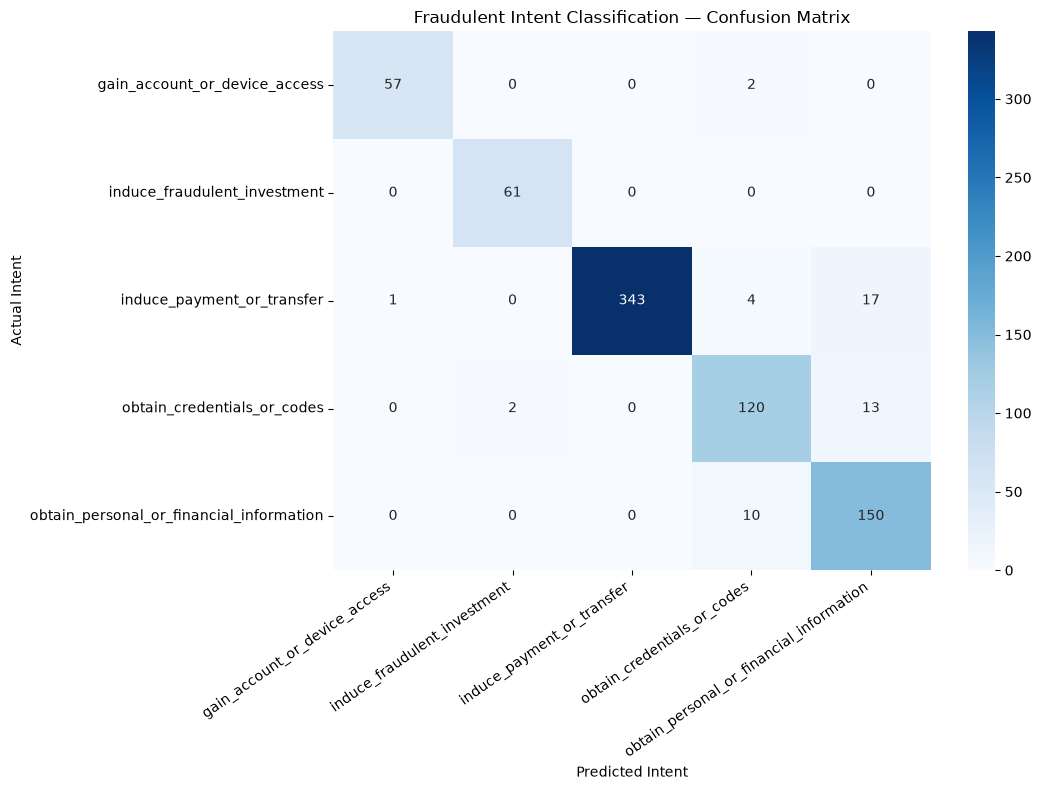

In [23]:
# Intent confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

intent_labels = sorted(y_intent.unique())

intent_cm = confusion_matrix(
    y_intent_val,
    y_intent_pred,
    labels=intent_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    intent_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_labels,
    yticklabels=intent_labels
)

plt.title("Fraudulent Intent Classification — Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
# Inspect misclassified intent narratives

intent_errors = pd.DataFrame({
    "actual": y_intent_val,
    "predicted": y_intent_pred,
    "text": X_val_text
})

intent_errors = intent_errors[
    intent_errors["actual"] != intent_errors["predicted"]
].copy()

print("Total misclassifications:", len(intent_errors))

display(
    pd.crosstab(
        intent_errors["actual"],
        intent_errors["predicted"]
    )
)

for idx, row in intent_errors.head(15).iterrows():
    print("\n" + "=" * 85)
    print("Record:", df.loc[idx, "record_id"])
    print("Actual intent:", row["actual"])
    print("Predicted intent:", row["predicted"])
    print("Text:", row["text"])

Total misclassifications: 49


predicted,gain_account_or_device_access,induce_fraudulent_investment,obtain_credentials_or_codes,obtain_personal_or_financial_information
actual,,,,
gain_account_or_device_access,0,0,2,0
induce_payment_or_transfer,1,0,4,17
obtain_credentials_or_codes,0,2,0,13
obtain_personal_or_financial_information,0,0,10,0



Record: SYN3C-00489
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Summit Federal Credit Union Alert] Foreign network connection detected from overseas IP in Atlanta, GA. Block access at [URL]

Record: SYN3C-00498
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Vanguard Bancorp Alert] Foreign network connection detected from overseas IP in Miami, FL. Block access at [URL]

Record: SYN3C-00500
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [First Crest Bank Alert] Foreign network connection detected from overseas IP in Phoenix, AZ. Block access at [URL]

Record: SYN3C-00504
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Pinnacle Bank Alert] Foreign network connection detected from overseas IP in Miami, FL. Block access at [URL]

Record:

In [25]:
# Find identical narratives with conflicting intent labels

narrative_intent_counts = (
    df.groupby("normalized_text")["fraudulent_intent"]
    .nunique()
)

conflicting_narratives = narrative_intent_counts[
    narrative_intent_counts > 1
]

print("Unique narratives:", df["normalized_text"].nunique())
print("Narratives with conflicting intent labels:", len(conflicting_narratives))

conflict_details = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "fraudulent_intent"])
    .size()
    .reset_index(name="count")
    .sort_values(["normalized_text", "fraudulent_intent"])
)

display(conflict_details.head(30))

Unique narratives: 7400
Narratives with conflicting intent labels: 129


,normalized_text,fraudulent_intent,count
0,🔔 [Apex ID Services Notice] Airfare cancellati...,induce_payment_or_transfer,3
1,🔔 [Apex ID Services Notice] Airfare cancellati...,obtain_personal_or_financial_information,1
2,🔔 [Apex ID Services Notice] Commercial freight...,induce_payment_or_transfer,1
3,🔔 [Apex ID Services Notice] Commercial freight...,obtain_personal_or_financial_information,1
4,🔔 [Apex ID Services Notice] Part-time e-commer...,induce_payment_or_transfer,3
5,🔔 [Apex ID Services Notice] Part-time e-commer...,obtain_personal_or_financial_information,1
6,🔔 [Apex ID Services Notice] Prorated enterpris...,gain_account_or_device_access,1
7,🔔 [Apex ID Services Notice] Prorated enterpris...,induce_payment_or_transfer,1
8,🔔 [Apex ID Services Notice] Prorated enterpris...,obtain_personal_or_financial_information,1
9,🔔 [Apex National Bank Alert] Home equity liqui...,obtain_credentials_or_codes,2


In [26]:
# Quantify conflicting narrative labels

conflict_groups = (
    df.groupby("normalized_text")
    .agg(
        record_count=("record_id", "size"),
        intent_count=("fraudulent_intent", "nunique"),
        intents=("fraudulent_intent", lambda x: sorted(x.unique()))
    )
    .query("intent_count > 1")
    .sort_values("record_count", ascending=False)
)

conflicting_record_count = conflict_groups["record_count"].sum()

print("Distinct conflicting narratives:", len(conflict_groups))
print("Records belonging to conflicting narratives:", conflicting_record_count)
print(f"Percentage of dataset: {conflicting_record_count / len(df) * 100:.2f}%")

print("\nConflicting intent combinations:")
display(
    conflict_groups["intents"]
    .value_counts()
    .rename_axis("intent_combination")
    .reset_index(name="narrative_count")
)

print("\nLargest conflicting groups:")
display(conflict_groups.head(20))

Distinct conflicting narratives: 129
Records belonging to conflicting narratives: 438
Percentage of dataset: 5.62%

Conflicting intent combinations:


,intent_combination,narrative_count
0,"[induce_payment_or_transfer, obtain_personal_o...",35
1,"[obtain_credentials_or_codes, obtain_personal_...",31
2,"[induce_payment_or_transfer, obtain_credential...",19
3,"[induce_payment_or_transfer, obtain_credential...",10
4,"[gain_account_or_device_access, induce_payment...",7
5,"[gain_account_or_device_access, induce_payment...",5
6,"[gain_account_or_device_access, obtain_credent...",5
7,"[gain_account_or_device_access, obtain_persona...",5
8,"[gain_account_or_device_access, induce_payment...",3
9,"[gain_account_or_device_access, obtain_credent...",3



Largest conflicting groups:


,record_count,intent_count,intents
normalized_text,,,
🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL],16,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] Audit docket #[IDENTIFIER] determined unresolved income tax liability of [AMOUNT]. Settle debt at [URL],16,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] W-2 withholding payroll discrepancy created unpaid statutory balance of [AMOUNT]. Reconcile file at [URL],15,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] Formal federal tax lien #[IDENTIFIER] recorded for delinquent taxes of [AMOUNT]. Resolve lien at [URL],13,3,"[induce_payment_or_transfer, obtain_credential..."
🔔 [Restitution Office] Consumer protection audit approved restitution payout of [AMOUNT]. Release funds at [URL],10,3,"[gain_account_or_device_access, induce_payment..."
🚨 [Tax Revenue Bureau] Quarterly tax underpayment assessment file #[IDENTIFIER] totaling [AMOUNT] due. Settle penalty at [URL],10,3,"[induce_payment_or_transfer, obtain_credential..."
🔔 [Restitution Office] Judicial restitution decree #[IDENTIFIER] allocated [AMOUNT] in damages. Claim restitution at [URL],9,3,"[gain_account_or_device_access, induce_payment..."
🚨 [Centennial Mutual Alert] Access placed on hold after three invalid passcode attempts. Unlock profile at [URL],8,3,"[gain_account_or_device_access, obtain_credent..."
🔔 [CloudShield Security Notice] Duplicate overpayment credit of [AMOUNT] deposited to your profile. Review ledger at [URL],7,3,"[gain_account_or_device_access, induce_payment..."


In [27]:
# Check conflicting narratives across dataset partitions

conflict_partition_details = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "split_partition"])
    .agg(
        records=("record_id", "size"),
        intent_count=("fraudulent_intent", "nunique"),
        intents=("fraudulent_intent", lambda x: sorted(x.unique()))
    )
    .reset_index()
)

print("Conflicting narratives by partition:")
display(
    conflict_partition_details.groupby("split_partition").agg(
        narrative_groups=("normalized_text", "nunique"),
        records=("records", "sum"),
        groups_with_internal_conflicts=("intent_count", lambda x: (x > 1).sum())
    )
)

print("\nNarratives appearing in multiple partitions:")
narrative_partition_counts = (
    conflict_partition_details.groupby("normalized_text")["split_partition"]
    .nunique()
)

print(
    "Conflicting narratives spanning multiple partitions:",
    (narrative_partition_counts > 1).sum()
)

print("\nDetailed partition examples:")
display(conflict_partition_details.head(20))

Conflicting narratives by partition:


,narrative_groups,records,groups_with_internal_conflicts
split_partition,,,
test,16,46,16
train,98,348,98
val,15,44,15



Narratives appearing in multiple partitions:
Conflicting narratives spanning multiple partitions: 0

Detailed partition examples:


,normalized_text,split_partition,records,intent_count,intents
0,🔔 [Apex ID Services Notice] Airfare cancellati...,train,4,2,"[induce_payment_or_transfer, obtain_personal_o..."
1,🔔 [Apex ID Services Notice] Commercial freight...,test,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
2,🔔 [Apex ID Services Notice] Part-time e-commer...,test,4,2,"[induce_payment_or_transfer, obtain_personal_o..."
3,🔔 [Apex ID Services Notice] Prorated enterpris...,test,3,3,"[gain_account_or_device_access, induce_payment..."
4,🔔 [Apex National Bank Alert] Home equity liqui...,train,3,2,"[obtain_credentials_or_codes, obtain_personal_..."
5,🔔 [AppleCash Express Alert] Digital scratch-of...,train,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
6,🔔 [AppleCash Express Alert] Official grant sta...,train,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
7,🔔 [AppleCash Express Alert] Selected for execu...,train,5,2,"[induce_payment_or_transfer, obtain_personal_o..."
8,🔔 [AppleCash Express Alert] Unclaimed complete...,train,3,2,"[induce_payment_or_transfer, obtain_personal_o..."
9,🔔 [AuthGuardian Inc. Notice] Airfare cancellat...,train,5,3,"[gain_account_or_device_access, induce_payment..."


In [28]:
# Inspect intent evidence for conflicting narratives

conflict_evidence = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "fraudulent_intent"])
    .agg(
        records=("record_id", "size"),
        evidence_values=("primary_intent_evidence", "nunique"),
        evidence_samples=(
            "primary_intent_evidence",
            lambda x: list(x.unique())[:3]
        ),
        scenario_families=("scenario_family", "nunique")
    )
    .reset_index()
)

print("Conflicting narrative-label combinations:", len(conflict_evidence))

display(conflict_evidence.head(25))

Conflicting narrative-label combinations: 281


,normalized_text,fraudulent_intent,records,evidence_values,evidence_samples,scenario_families
0,🔔 [Apex ID Services Notice] Airfare cancellati...,induce_payment_or_transfer,3,1,"[{""start_char"": 98, ""end_char"": 152, ""span_tex...",1
1,🔔 [Apex ID Services Notice] Airfare cancellati...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 96, ""end_char"": 150, ""span_tex...",1
2,🔔 [Apex ID Services Notice] Commercial freight...,induce_payment_or_transfer,1,1,"[{""start_char"": 105, ""end_char"": 160, ""span_te...",1
3,🔔 [Apex ID Services Notice] Commercial freight...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 107, ""end_char"": 162, ""span_te...",1
4,🔔 [Apex ID Services Notice] Part-time e-commer...,induce_payment_or_transfer,3,1,"[{""start_char"": 108, ""end_char"": 160, ""span_te...",1
5,🔔 [Apex ID Services Notice] Part-time e-commer...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 108, ""end_char"": 160, ""span_te...",1
6,🔔 [Apex ID Services Notice] Prorated enterpris...,gain_account_or_device_access,1,1,"[{""start_char"": 91, ""end_char"": 146, ""span_tex...",1
7,🔔 [Apex ID Services Notice] Prorated enterpris...,induce_payment_or_transfer,1,1,"[{""start_char"": 93, ""end_char"": 148, ""span_tex...",1
8,🔔 [Apex ID Services Notice] Prorated enterpris...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 93, ""end_char"": 148, ""span_tex...",1
9,🔔 [Apex National Bank Alert] Home equity liqui...,obtain_credentials_or_codes,2,1,"[{""start_char"": 95, ""end_char"": 148, ""span_tex...",1


In [29]:
# Inspect evidence spans for representative conflicting narratives

representative_texts = conflict_groups.head(5).index.tolist()

for narrative in representative_texts:
    print("\n" + "=" * 100)
    print("NARRATIVE:")
    print(narrative)

    examples = df[df["normalized_text"] == narrative][
        ["record_id", "fraudulent_intent", "primary_intent_evidence"]
    ]

    display(examples)


NARRATIVE:
🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4527,SYN3C-04528,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4528,SYN3C-04529,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4530,SYN3C-04531,obtain_personal_or_financial_information,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4533,SYN3C-04534,induce_payment_or_transfer,"{""start_char"": 98, ""end_char"": 161, ""span_text..."
4535,SYN3C-04536,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4536,SYN3C-04537,obtain_credentials_or_codes,"{""start_char"": 98, ""end_char"": 161, ""span_text..."
4542,SYN3C-04543,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4545,SYN3C-04546,obtain_personal_or_financial_information,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4546,SYN3C-04547,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4547,SYN3C-04548,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] Audit docket #[IDENTIFIER] determined unresolved income tax liability of [AMOUNT]. Settle debt at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4202,SYN3C-04203,obtain_credentials_or_codes,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4206,SYN3C-04207,obtain_personal_or_financial_information,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4208,SYN3C-04209,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4211,SYN3C-04212,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4215,SYN3C-04216,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4216,SYN3C-04217,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4226,SYN3C-04227,obtain_credentials_or_codes,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4233,SYN3C-04234,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 161, ""span_tex..."
4237,SYN3C-04238,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 161, ""span_tex..."
4238,SYN3C-04239,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] W-2 withholding payroll discrepancy created unpaid statutory balance of [AMOUNT]. Reconcile file at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4441,SYN3C-04442,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4442,SYN3C-04443,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4450,SYN3C-04451,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4457,SYN3C-04458,obtain_credentials_or_codes,"{""start_char"": 104, ""end_char"": 167, ""span_tex..."
4460,SYN3C-04461,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4474,SYN3C-04475,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4476,SYN3C-04477,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4481,SYN3C-04482,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4491,SYN3C-04492,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4495,SYN3C-04496,obtain_credentials_or_codes,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] Formal federal tax lien #[IDENTIFIER] recorded for delinquent taxes of [AMOUNT]. Resolve lien at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4283,SYN3C-04284,obtain_personal_or_financial_information,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4299,SYN3C-04300,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4305,SYN3C-04306,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4308,SYN3C-04309,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4319,SYN3C-04320,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4331,SYN3C-04332,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4333,SYN3C-04334,induce_payment_or_transfer,"{""start_char"": 99, ""end_char"": 160, ""span_text..."
4338,SYN3C-04339,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4343,SYN3C-04344,obtain_credentials_or_codes,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4347,SYN3C-04348,obtain_personal_or_financial_information,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."



NARRATIVE:
🔔 [Restitution Office] Consumer protection audit approved restitution payout of [AMOUNT]. Release funds at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
6840,SYN3C-06841,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6847,SYN3C-06848,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6859,SYN3C-06860,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6866,SYN3C-06867,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6868,SYN3C-06869,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6890,SYN3C-06891,obtain_credentials_or_codes,"{""start_char"": 89, ""end_char"": 152, ""span_text..."
6897,SYN3C-06898,obtain_credentials_or_codes,"{""start_char"": 89, ""end_char"": 152, ""span_text..."
6910,SYN3C-06911,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6915,SYN3C-06916,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6917,SYN3C-06918,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."


In [30]:
# Compare actual evidence span text across conflicting intent labels

representative_texts = conflict_groups.head(3).index.tolist()

for narrative in representative_texts:
    print("\n" + "=" * 100)
    print("NARRATIVE:", narrative)

    examples = df.loc[
        df["normalized_text"] == narrative,
        ["record_id", "fraudulent_intent", "primary_intent_evidence"]
    ].sort_values("fraudulent_intent")

    for _, row in examples.iterrows():
        evidence = row["primary_intent_evidence"]

        if isinstance(evidence, str):
            evidence = json.loads(evidence)

        print(
            f"\n{row['record_id']} | {row['fraudulent_intent']}"
        )

        if isinstance(evidence, dict):
            print("Span:", repr(evidence.get("span_text")))
        elif isinstance(evidence, list):
            print("Spans:", [item.get("span_text") for item in evidence])
        else:
            print("Evidence:", repr(evidence))


NARRATIVE: 🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL]

SYN3C-04528 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04529 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04534 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04536 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04543 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04547 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04548 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04551 | induce_payment_or_transfer
Span: 'Pay assessment